# Assignment 2.2: Individual Multimodal Movie Genre Classification
**Student:** Kush Atulkumar Patel  |  **Student ID:** A3015439  |  **Adelaide University**

**Research question:** How do image-only, text-only, early, late, gated and self-attention fusion compare on multi-label movie genre prediction from MM-IMDb posters and plot summaries?


## Environment and reproducibility

Import the same core PyTorch, scikit-learn, BERT and Matplotlib methods used in the course practicals. Fix random seeds, record the device and use explicit code comments.

In [3]:
# ---- Step 1: Imports and deterministic setup ----
from pathlib import Path
import json, tarfile, random, time, copy, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MultiLabelBinarizer, StandardScaler
from sklearn.metrics import f1_score, precision_score, recall_score, average_precision_score
import torch
from tqdm.auto import tqdm
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from transformers import AutoTokenizer, AutoModel
import hashlib
import warnings
import os
import shutil
from sklearn.metrics import classification_report
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.set_num_threads(min(4, torch.get_num_threads()))
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, "| Torch:", torch.__version__)

Device: cuda | Torch: 2.14.1+cu130


## Dataset loading

Data loading checks Google Drive and local storage. It does not download the 8.7 GB archive if a valid local copy or extracted dataset exists. Extract archive members safely, then align each movie JSON record to its poster and plot.

In [4]:
# ---- Step 2A: Restore existing Google Drive backup when available ----
from pathlib import Path

ROOT = Path('/content') if Path('/content').exists() else Path.cwd()
ARCHIVE = ROOT / 'mmimdb.tar.gz'
DATA_DIR = ROOT / 'mmimdb'
CACHE = ROOT / 'feature_cache'
BACKUP_DIR = Path('/content/drive/MyDrive/MMIMDb_Backup')

if ROOT == Path('/content'):
    try:
        from google.colab import drive
        drive.mount('/content/drive')
    except ImportError:
        print('Not in Google Colab: using local files.')

if not ARCHIVE.exists() and (BACKUP_DIR / 'mmimdb.tar.gz').exists():
    print('Restoring dataset archive from Google Drive...')
    shutil.copy2(BACKUP_DIR / 'mmimdb.tar.gz', ARCHIVE)

if not CACHE.exists() and (BACKUP_DIR / 'feature_cache').exists():
    print('Restoring feature cache from Google Drive...')
    shutil.copytree(BACKUP_DIR / 'feature_cache', CACHE)

if not (DATA_DIR.exists() and any(DATA_DIR.rglob('*.json'))) and not ARCHIVE.exists():
    raise FileNotFoundError(
        'Dataset not found. Upload mmimdb.tar.gz to /content, or restore it to '
        '/content/drive/MyDrive/MMIMDb_Backup/mmimdb.tar.gz. '
        'Source: https://archive.org/download/mmimdb/mmimdb.tar.gz'
    )
print('Archive:', ARCHIVE, '| exists:', ARCHIVE.exists())
print('Feature cache:', CACHE, '| exists:', CACHE.exists())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Archive: /content/mmimdb.tar.gz | exists: True
Feature cache: /content/feature_cache | exists: True


In [5]:
# ---- Step 2B: Safely extract archive if necessary ----
if not (DATA_DIR.exists() and any(DATA_DIR.rglob("*.json"))):
    if not ARCHIVE.exists():
        raise FileNotFoundError("Download the MM-IMDb archive from https://archive.org/download/mmimdb/mmimdb.tar.gz and place it beside this notebook.")
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    # Extract only paths inside the destination to avoid unsafe archive members.
    with tarfile.open(ARCHIVE, "r:gz") as tar:
        base = DATA_DIR.resolve()
        for member in tar:
            target = (DATA_DIR / member.name).resolve()
            if not target.is_relative_to(base):
                raise ValueError(f"Unsafe archive path: {member.name}")
        tar.extractall(DATA_DIR, filter="data")
print("Dataset directory:", DATA_DIR.resolve())

Dataset directory: /content/mmimdb


In [6]:
# ---- Step 2C: Align JSON metadata, plot summaries and posters ----
records = []
for jf in tqdm(sorted(DATA_DIR.rglob("*.json")), desc="Reading metadata"):
    try:
        obj = json.loads(jf.read_text(encoding="utf-8"))
        genres = obj.get("genres", [])
        if isinstance(genres, str): genres = [genres]
        plot = obj.get("plot", "")
        if isinstance(plot, list): plot = " ".join(str(p) for p in plot)
        if not isinstance(plot, str): plot = str(plot)
        poster = next((p for ext in (".jpeg",".jpg",".png") if (jf.with_suffix(ext)).exists()
                       for p in [jf.with_suffix(ext)]), None)
        if genres and plot.strip() and poster:
            records.append({"id": jf.stem, "plot": plot, "genres": genres, "poster": str(poster)})
    except (ValueError, UnicodeError, OSError, TypeError):
        continue
df = pd.DataFrame(records)
if df.empty:
    raise RuntimeError("No aligned records found. Inspect archive layout and JSON keys.")
df = df.drop_duplicates(subset=["id"]).reset_index(drop=True)
df["plot_words"] = df["plot"].str.split().str.len()
df["n_genres"] = df["genres"].apply(len)
print("Aligned movies:", len(df))
print(df[["plot_words","n_genres"]].describe())
print("Duplicate plots:", int(df["plot"].duplicated().sum()))
print("Poster files found:", df["poster"].notna().sum())

Reading metadata:   0%|          | 0/25960 [00:00<?, ?it/s]

Aligned movies: 25959
         plot_words      n_genres
count  25959.000000  25959.000000
mean     161.512693      2.487384
std      146.651160      1.189360
min        1.000000      1.000000
25%       63.000000      2.000000
50%      117.000000      2.000000
75%      213.000000      3.000000
max     1895.000000     10.000000
Duplicate plots: 14
Poster files found: 25959


## Dataset quality assessment

Audit poster dimensions, corrupted files, oversized-image warnings, plot length, duplicate text, missing metadata and genre frequency. Oversized posters are flagged and skipped safely in the feature loader if they cannot be decoded, rather than disabling Pillow safeguards.

In [7]:
# ---- Step 3A: Poster size and corruption audit ----
# Poster quality audit: read headers and verify decoding without allocating full-size arrays.
# PIL's decompression-bomb warnings are treated as flags, not disabled.
import warnings
from PIL import UnidentifiedImageError
poster_rows = []
for poster_path in tqdm(df["poster"].tolist(), desc="Auditing posters"):
    width = height = np.nan
    status = "ok"
    try:
        with warnings.catch_warnings(record=True) as seen:
            warnings.simplefilter("always", Image.DecompressionBombWarning)
            with Image.open(poster_path) as im:
                width, height = im.size
                im.verify()
            if any(issubclass(w.category, Image.DecompressionBombWarning) for w in seen):
                status = "oversized_warning"
    except (OSError, ValueError, UnidentifiedImageError, Image.DecompressionBombError) as exc:
        status = type(exc).__name__
    poster_rows.append({"poster": poster_path, "width": width, "height": height,
                        "pixels": width*height, "status": status})
image_quality_df = pd.DataFrame(poster_rows)
print("Poster audit summary:")
print(image_quality_df["status"].value_counts(dropna=False).to_string())
display(image_quality_df[["width", "height", "pixels"]].describe())
print("WARNING: This audit does not remove records. Decode errors in the actual feature loader still require investigation.")

Auditing posters:   0%|          | 0/25959 [00:00<?, ?it/s]

Poster audit summary:
status
ok                   25935
oversized_warning       24


,width,height,pixels
count,25959.000000,25959.000000,2.595900e+04
mean,634.971840,902.686968,1.171158e+06
std,660.084071,926.851377,4.568217e+06
min,7.000000,5.000000,3.500000e+01
25%,333.000000,475.000000,1.586500e+05
50%,355.000000,500.000000,1.775000e+05
75%,682.000000,1014.000000,6.976860e+05
max,16200.000000,12257.000000,1.749600e+08


Movies: 25945
Genres: 23
Label matrix: (25945, 23)
Genre count: 23
Drama          13962.0
Comedy          8585.0
Romance         5363.0
Thriller        5192.0
Crime           3838.0
Action          3549.0
Adventure       2708.0
Horror          2702.0
Documentary     2078.0
Mystery         2056.0
Sci-Fi          1990.0
Fantasy         1931.0
dtype: float32


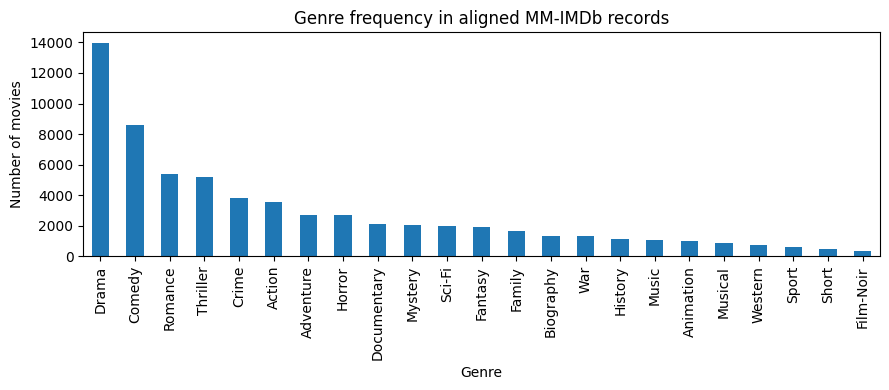

In [8]:
# ---- Step 3B: Deduplicate and construct the 23-genre multi-label target ----
# Prevent identical plot text from appearing in more than one split.
df = df.drop_duplicates(subset=["plot"]).reset_index(drop=True)
excluded_genres = {
    "Adult", "News", "Reality-TV", "Talk-Show"
}

df["genres_23"] = df["genres"].apply(
    lambda labels: [
        genre for genre in labels
        if genre not in excluded_genres
    ]
)

df = df[df['genres_23'].map(len) > 0].reset_index(drop=True)
assert len(df) > 0

mlb = MultiLabelBinarizer()
Y = mlb.fit_transform(df["genres_23"]).astype(np.float32)

print("Movies:", len(df))
print("Genres:", len(mlb.classes_))
print("Label matrix:", Y.shape)
print("Genre count:", len(mlb.classes_))
if len(mlb.classes_) != 23:
    raise ValueError(f'Expected 23 genres but found {len(mlb.classes_)}. Check labels and exclusions.')
print(pd.Series(Y.sum(axis=0), index=mlb.classes_).sort_values(ascending=False).head(12))
fig, ax = plt.subplots(figsize=(9,4))
pd.Series(Y.sum(axis=0), index=mlb.classes_).sort_values(ascending=False).plot.bar(ax=ax)
ax.set(title="Genre frequency in aligned MM-IMDb records", xlabel="Genre", ylabel="Number of movies")
plt.tight_layout(); plt.show()

## Dataset partitioning

A verified official split CSV with `id,split` columns when available. Otherwise use a reproducible 60/10/30 random split and report the deviation. Fit scalers on training data only. Select thresholds on validation data only.

In [9]:
# ---- Step 4A: Split movie IDs into train, validation and test ----
# If you have a verified official split CSV, place it at /content/mmimdb_official_splits.csv.
# Required columns: id, split; split values: train, val (or validation), test.
# Otherwise a deterministic random 60/10/30 split is used and MUST be disclosed in the report.
split_file = ROOT / 'mmimdb_official_splits.csv'
if split_file.exists():
    split_table = pd.read_csv(split_file, dtype={'id': str})
    assert {'id','split'}.issubset(split_table.columns)
    split_table['split'] = split_table['split'].str.lower().replace({'validation':'val'})
    assert not split_table['id'].duplicated().any(), 'Duplicate IDs in split file'
    assignments = df[['id']].merge(split_table[['id','split']], on='id', how='left', validate='one_to_one')
    assert assignments['split'].notna().all(), 'Official split file does not cover all retained IDs'
    assert set(assignments['split'].unique()) == {'train','val','test'}
    train_idx = np.flatnonzero(assignments['split'].eq('train').to_numpy())
    val_idx = np.flatnonzero(assignments['split'].eq('val').to_numpy())
    test_idx = np.flatnonzero(assignments['split'].eq('test').to_numpy())
    SPLIT_METHOD = 'supplied official split file'
else:
    indices = np.arange(len(df))
    train_idx, other_idx = train_test_split(indices, test_size=0.4, random_state=SEED)
    val_idx, test_idx = train_test_split(other_idx, test_size=0.75, random_state=SEED)
    SPLIT_METHOD = 'seeded random 60/10/30 (deviation from proposal)'
assert len(set(train_idx)&set(val_idx)) == len(set(train_idx)&set(test_idx)) == len(set(val_idx)&set(test_idx)) == 0
assert len(train_idx)+len(val_idx)+len(test_idx) == len(df)
print('Split method:', SPLIT_METHOD)
print('Train/validation/test:', len(train_idx), len(val_idx), len(test_idx))

Split method: seeded random 60/10/30 (deviation from proposal)
Train/validation/test: 15567 2594 7784


In [10]:
# ---- Step 4B: Prepare labels for each split ----
# Labels must be constructed AFTER the split and 23-genre target matrix.
y_tr = Y[train_idx].astype(np.float32)
y_va = Y[val_idx].astype(np.float32)
y_te = Y[test_idx].astype(np.float32)
print("Target shapes:", y_tr.shape, y_va.shape, y_te.shape)
assert y_tr.shape[1] == y_va.shape[1] == y_te.shape[1] == 23


Target shapes: (15567, 23) (2594, 23) (7784, 23)


## Image and text representation

Resize and normalise posters using EfficientNet-B0 preprocessing; tokenise summaries with `bert-base-uncased` and a 160-token limit. The pretrained encoders are frozen. Record actual WordPiece truncation rather than inferring it from word counts.

In [11]:
# ---- Step 5A: Dataset class, EfficientNet-B0 and BERT encoders ----
class MovieDataset(Dataset):
    def __init__(self, frame, indices, tokenizer, image_transform, max_length=160):
        self.frame = frame.iloc[indices].reset_index(drop=True)
        self.tokenizer = tokenizer
        self.image_transform = image_transform
        self.max_length = max_length
    def __len__(self): return len(self.frame)
    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        with Image.open(row["poster"]) as im:
            image = self.image_transform(im.convert("RGB"))
        tokens = self.tokenizer(row["plot"], max_length=self.max_length,
                                padding="max_length", truncation=True, return_tensors="pt")
        return image, tokens["input_ids"][0], tokens["attention_mask"][0]

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
image_transform = transforms.Compose([
    transforms.Resize((224,224)), transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])
image_encoder = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
image_encoder.classifier = nn.Identity()
image_encoder = image_encoder.to(DEVICE).eval()
text_encoder = AutoModel.from_pretrained("bert-base-uncased").to(DEVICE).eval()
for p in image_encoder.parameters(): p.requires_grad_(False)
for p in text_encoder.parameters(): p.requires_grad_(False)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 228MB/s]


model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Auditing BERT input lengths:   0%|          | 0/25945 [00:00<?, ?it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (577 > 512). Running this sequence through the model will result in indexing errors


BERT token length distribution:


,bert_tokens
count,25945.000000
mean,204.099904
std,182.253936
min,3.000000
25%,81.000000
50%,150.000000
75%,270.000000
max,2260.000000


Truncated inputs: 12040 of 25945 = 46.41 %


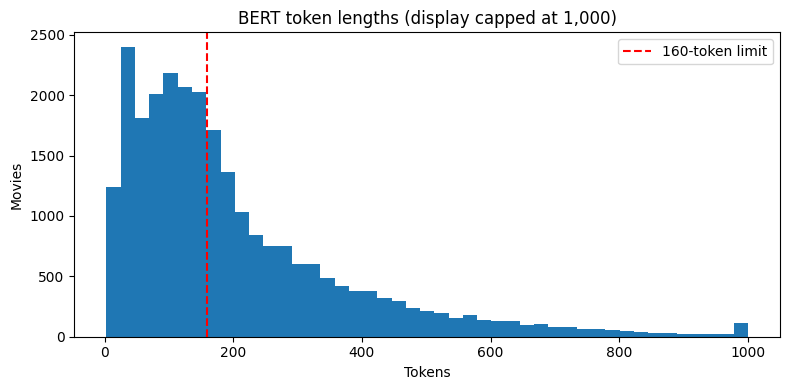

In [12]:
# ---- Step 5B: Measure WordPiece token truncation ----
# BERT uses word-piece tokens; word counts alone cannot establish truncation.
# Count tokens including special tokens, without changing the 160-token experiment.
BERT_MAX_LENGTH = 160
token_lengths = []
for plot_text in tqdm(df["plot"].tolist(), desc="Auditing BERT input lengths"):
    token_lengths.append(len(tokenizer.encode(str(plot_text), add_special_tokens=True, truncation=False)))
text_audit_df = pd.DataFrame({"id": df["id"].astype(str),
                              "bert_tokens": token_lengths,
                              "exceeds_160_tokens": np.array(token_lengths)>BERT_MAX_LENGTH})
print("BERT token length distribution:")
display(text_audit_df["bert_tokens"].describe())
print("Truncated inputs:", int(text_audit_df["exceeds_160_tokens"].sum()),
      "of", len(text_audit_df),
      "=", round(100*text_audit_df["exceeds_160_tokens"].mean(),2), "%")
fig, ax = plt.subplots(figsize=(8,4))
ax.hist(np.minimum(token_lengths,1000), bins=45)
ax.axvline(BERT_MAX_LENGTH, color="red", linestyle="--", label="160-token limit")
ax.set(title="BERT token lengths (display capped at 1,000)", xlabel="Tokens", ylabel="Movies")
ax.legend(); fig.tight_layout(); plt.show()

## Feature extraction

EfficientNet-B0 produces 1,280 image features; BERT mean pooling produces 768 text features. Cached features are reused only if movie IDs, model names, preprocessing and split ordering match. The feature stage timing includes cache loading when applicable.

In [13]:
# ---- Step 6A: Feature extraction with verified cache keys ----
import hashlib
CACHE.mkdir(parents=True, exist_ok=True)
BATCH_SIZE = 16 if DEVICE.type == 'cuda' else 4
# Legacy caches from the proposal notebook do not contain row IDs. To avoid mixing
# features from different movies, they are NEVER silently accepted.
# Set to True ONLY when you have verified the same dataset, preprocessing, split,
# row ordering, image encoder and text encoder as the original cache run.
TRUST_LEGACY_CACHE = False

def extract_features(indices, name):
    ids = df.iloc[indices]['id'].astype(str).to_numpy()
    digest = hashlib.sha256(('\n'.join(ids) + '|efficientnet_b0|bert-base-uncased|160|224x224|imagenet_norm|mean_pool').encode()).hexdigest()
    cache_path = CACHE / f'{name}_seed{SEED}.npz'
    if cache_path.exists():
        with np.load(cache_path) as arr:
            valid = ('digest' in arr and str(arr['digest'].item()) == digest
                     and len(arr['image']) == len(indices)
                     and arr['image'].shape[1] == 1280 and arr['text'].shape[1] == 768)
            legacy = ('digest' not in arr and TRUST_LEGACY_CACHE
                      and len(arr['image']) == len(indices)
                      and arr['image'].shape[1] == 1280 and arr['text'].shape[1] == 768)
            if valid or legacy:
                print(f'Using {"verified" if valid else "manually trusted LEGACY"} {name} feature cache')
                return arr['image'].copy(), arr['text'].copy()
        print(f'Cache mismatch for {name}; recomputing features')
    loader = DataLoader(MovieDataset(df, indices, tokenizer, image_transform),
                        batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    image_features, text_features = [], []
    for imgs, ids_batch, mask in tqdm(loader, desc=f'Extracting {name}'):
        with torch.inference_mode():
            im = image_encoder(imgs.to(DEVICE))
            tx = text_encoder(input_ids=ids_batch.to(DEVICE),
                              attention_mask=mask.to(DEVICE)).last_hidden_state
            weights = mask.to(DEVICE).unsqueeze(-1)
            tx = (tx * weights).sum(dim=1) / weights.sum(dim=1).clamp_min(1)
        image_features.append(im.cpu().numpy())
        text_features.append(tx.cpu().numpy())
    image_arr = np.concatenate(image_features).astype(np.float32)
    text_arr = np.concatenate(text_features).astype(np.float32)
    np.savez_compressed(cache_path, image=image_arr, text=text_arr, digest=np.array(digest))
    return image_arr, text_arr

start_extract = time.perf_counter()
Xi_tr, Xt_tr = extract_features(train_idx, 'train')
Xi_va, Xt_va = extract_features(val_idx, 'val')
Xi_te, Xt_te = extract_features(test_idx, 'test')
FEATURE_STAGE_SECONDS = time.perf_counter()-start_extract
print('Feature stage seconds (may include verified cache loading):', round(FEATURE_STAGE_SECONDS, 1))
print('Feature dimensions:', Xi_tr.shape[1], Xt_tr.shape[1])

Cache mismatch for train; recomputing features


Extracting train:   0%|          | 0/973 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (174960000 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (97888494 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (99083998 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (97200000 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (97778814 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS

Cache mismatch for val; recomputing features


Extracting val:   0%|          | 0/163 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (97200000 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (97212000 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


Cache mismatch for test; recomputing features


Extracting test:   0%|          | 0/487 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (101769871 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (92984898 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (100233700 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (97143904 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (97200000 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DO

Feature stage seconds (may include verified cache loading): 627.8
Feature dimensions: 1280 768


In [14]:
# ---- Step 6B: Standardise image and text features using training data ----
sc_i = StandardScaler().fit(Xi_tr)
sc_t = StandardScaler().fit(Xt_tr)
Xi_tr, Xi_va, Xi_te = [sc_i.transform(x).astype("float32") for x in (Xi_tr,Xi_va,Xi_te)]
Xt_tr, Xt_va, Xt_te = [sc_t.transform(x).astype("float32") for x in (Xt_tr,Xt_va,Xt_te)]
y_tr, y_va, y_te = Y[train_idx], Y[val_idx], Y[test_idx]

## Classification architectures

The experiments compare image-only, text-only, early concatenation, a simplified gated intermediate fusion, and 4-head self-attention. A sixth method, late fusion, is formed by combining image-only and text-only probabilities. These use `BCEWithLogitsLoss`, `AdamW`, dropout and validation-based early stopping as in the practicals. **The simplified gate is not the published GMU.**

In [15]:
# ---- Step 7A: Model architecture, prediction and early stopping ----
class FusionNet(nn.Module):
    def __init__(self, image_dim, text_dim, n_classes, mode="early", hidden=256, dropout=0.3):
        super().__init__()
        self.mode = mode
        self.image_proj = nn.Sequential(nn.Linear(image_dim, hidden), nn.ReLU())
        self.text_proj = nn.Sequential(nn.Linear(text_dim, hidden), nn.ReLU())
        if mode == "early": in_dim = image_dim + text_dim
        elif mode in ("image","text","gated","attention"): in_dim = hidden
        else: raise ValueError(mode)
        if mode == "gated":
            self.gate = nn.Linear(hidden*2, hidden)
        if mode == "attention":
            self.cross_attention = nn.MultiheadAttention(hidden, num_heads=4, dropout=dropout, batch_first=True)
        self.head = nn.Sequential(nn.Linear(in_dim, hidden), nn.ReLU(),
                                  nn.Dropout(dropout), nn.Linear(hidden, n_classes))
    def forward(self, image, text):
        if self.mode == "early": z = torch.cat([image, text], dim=1)
        elif self.mode == "image": z = self.image_proj(image)
        elif self.mode == "text": z = self.text_proj(text)
        elif self.mode == "gated":
            a, b = self.image_proj(image), self.text_proj(text)
            gate = torch.sigmoid(self.gate(torch.cat([a,b], dim=1)))
            z = gate*a + (1-gate)*b
        else:  # cross-attention over image and text feature tokens
            tokens = torch.stack([self.image_proj(image), self.text_proj(text)], dim=1)
            attended, _ = self.cross_attention(tokens, tokens, tokens, need_weights=False)
            z = attended.mean(dim=1)
        return self.head(z)

def predict_prob(model, xi, xt, batch_size=512):
    # Predict in batches to avoid a large GPU allocation.
    model.eval()
    predictions = []
    with torch.inference_mode():
        for start in range(0, len(xi), batch_size):
            end = start + batch_size
            image_batch = torch.from_numpy(xi[start:end]).to(DEVICE)
            text_batch = torch.from_numpy(xt[start:end]).to(DEVICE)
            probabilities = torch.sigmoid(model(image_batch, text_batch))
            predictions.append(probabilities.cpu().numpy())
    return np.concatenate(predictions, axis=0)

def train_model(mode, epochs=30, patience=5, lr=1e-3):
    model = FusionNet(Xi_tr.shape[1], Xt_tr.shape[1], y_tr.shape[1], mode).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    # Class-weighted BCE reduces the influence of dominant genres.
    # Validation micro-F1 is the declared stopping metric (not validation loss).
    positives = y_tr.sum(axis=0)
    weights = np.clip((len(y_tr)-positives)/np.maximum(positives,1), 1, 20)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(weights,device=DEVICE,dtype=torch.float32))
    loader = DataLoader(torch.utils.data.TensorDataset(
        torch.from_numpy(Xi_tr),torch.from_numpy(Xt_tr),torch.from_numpy(y_tr)),
        batch_size=128, shuffle=True)
    best, best_score, wait, history = None, -1, 0, []
    for epoch in range(epochs):
        model.train(); losses=[]
        for a,b,y in loader:
            optimizer.zero_grad()
            loss = loss_fn(model(a.to(DEVICE),b.to(DEVICE)),y.to(DEVICE))
            loss.backward(); optimizer.step()
            losses.append(float(loss.item()))
        val_probs = predict_prob(model,Xi_va,Xt_va)
        score = f1_score(y_va,val_probs>=0.5,average="micro",zero_division=0)
        history.append({"epoch":epoch+1,"train_loss":np.mean(losses),"val_micro_f1":score})
        if score > best_score + 1e-4:
            best_score, best, wait = score, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience: break
    model.load_state_dict(best)
    return model, pd.DataFrame(history)

## Model training

The same data split and preprocessing for a fair comparison. Each model records epoch history and training time. Do not evaluate the test set until all training and validation choices are complete.

In [16]:
# ---- Step 8A: Fit image, text, early, gated and attention classifiers ----
models_fit, histories, train_seconds = {}, {}, {}
for mode in ("image","text","early","gated","attention"):
    t0=time.perf_counter()
    models_fit[mode], histories[mode] = train_model(mode)
    train_seconds[mode] = time.perf_counter()-t0
    print(mode, "best validation micro-F1:", round(histories[mode]["val_micro_f1"].max(),4),
          "training seconds:", round(train_seconds[mode],1))

image best validation micro-F1: 0.4236 training seconds: 7.9
text best validation micro-F1: 0.6304 training seconds: 9.5
early best validation micro-F1: 0.6436 training seconds: 8.0
gated best validation micro-F1: 0.6413 training seconds: 7.3
attention best validation micro-F1: 0.6091 training seconds: 12.7


## Validation and threshold selection

Select a convex image/text probability weight and a global multilabel threshold for each model using validation micro-F1. The held-out test set remains untouched.

In [17]:
# ---- Step 9A: Validation-only late fusion and thresholds ----
val_img = predict_prob(models_fit["image"],Xi_va,Xt_va)
val_txt = predict_prob(models_fit["text"],Xi_va,Xt_va)
best_weight, best_f1 = 0.5, -1
for w in np.linspace(0,1,21):
    p = w*val_img + (1-w)*val_txt
    f = f1_score(y_va,p>=0.5,average="micro",zero_division=0)
    if f>best_f1: best_weight,best_f1 = float(w),float(f)
print("Late-fusion image weight:",best_weight,"validation micro-F1:",best_f1)

def select_threshold(probs):
    scores=[(f1_score(y_va,probs>=t,average="micro",zero_division=0),t)
            for t in np.arange(0.2,0.81,0.05)]
    return float(max(scores)[1])
val_probs = {m:predict_prob(net,Xi_va,Xt_va) for m,net in models_fit.items()}
val_probs["late"] = best_weight*val_img+(1-best_weight)*val_txt
thresholds = {m:select_threshold(p) for m,p in val_probs.items()}
print("Validation-selected thresholds:", thresholds)

Late-fusion image weight: 0.4 validation micro-F1: 0.6514787038347247
Validation-selected thresholds: {'image': 0.39999999999999997, 'text': 0.49999999999999994, 'early': 0.49999999999999994, 'gated': 0.49999999999999994, 'attention': 0.6499999999999999, 'late': 0.49999999999999994}


## Test-set evaluation

Evaluation includes micro, macro and weighted F1, precision, recall and average precision. The same test set for all six methods. A higher F1 is not guaranteed for the more complex attention model.

,micro_f1,macro_f1,weighted_f1,micro_precision,micro_recall,micro_average_precision,train_seconds
model,,,,,,,
late,0.6499,0.5906,0.6538,0.5923,0.7200,0.6570,NaN
gated,0.6397,0.5901,0.6485,0.5782,0.7157,0.6714,7.3311
early,0.6388,0.5853,0.6452,0.5676,0.7303,0.6737,8.0200
text,0.6265,0.5615,0.6359,0.5479,0.7316,0.6454,9.5236
attention,0.6214,0.5622,0.6300,0.5509,0.7126,0.6393,12.7386
image,0.4230,0.3097,0.4406,0.3284,0.5940,0.3454,7.9283


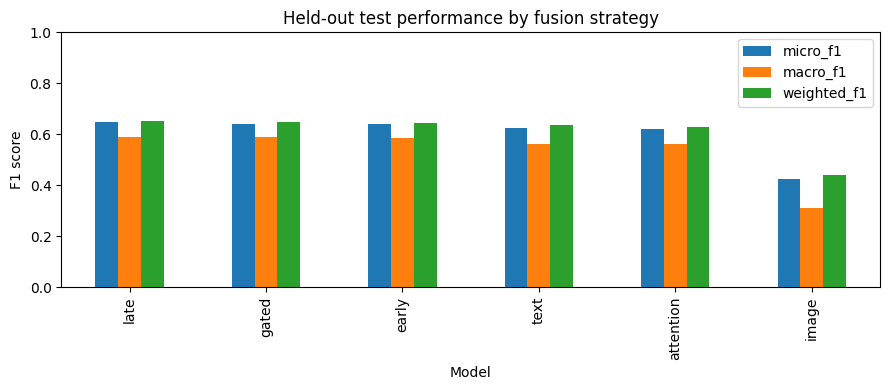

In [18]:
# ---- Step 10A: Final test-set metrics ----
test_probs = {m:predict_prob(net,Xi_te,Xt_te) for m,net in models_fit.items()}
test_probs["late"] = (best_weight*test_probs["image"]+
                       (1-best_weight)*test_probs["text"])
rows=[]
for name,p in test_probs.items():
    pred = (p>=thresholds[name]).astype(int)
    rows.append({"model":name,
                 "micro_f1":f1_score(y_te,pred,average="micro",zero_division=0),
                 "macro_f1":f1_score(y_te,pred,average="macro",zero_division=0),
                 "weighted_f1":f1_score(y_te,pred,average="weighted",zero_division=0),
                 "micro_precision":precision_score(y_te,pred,average="micro",zero_division=0),
                 "micro_recall":recall_score(y_te,pred,average="micro",zero_division=0),
                 "micro_average_precision":average_precision_score(y_te,p,average="micro"),
                 "train_seconds":train_seconds.get(name,np.nan)})
results=pd.DataFrame(rows).set_index("model").sort_values("micro_f1",ascending=False)
display(results.round(4))
results[["micro_f1","macro_f1","weighted_f1"]].plot.bar(figsize=(9,4))
plt.title("Held-out test performance by fusion strategy")
plt.xlabel("Model");plt.ylabel("F1 score");plt.ylim(0,1);plt.tight_layout();plt.show()

## Overfitting and genre-level performance

Display training loss and validation F1 on separate axes because they are different metrics. Also compare train and validation micro-F1 at each model's validation-selected threshold, then calculate the best model's per-genre F1.

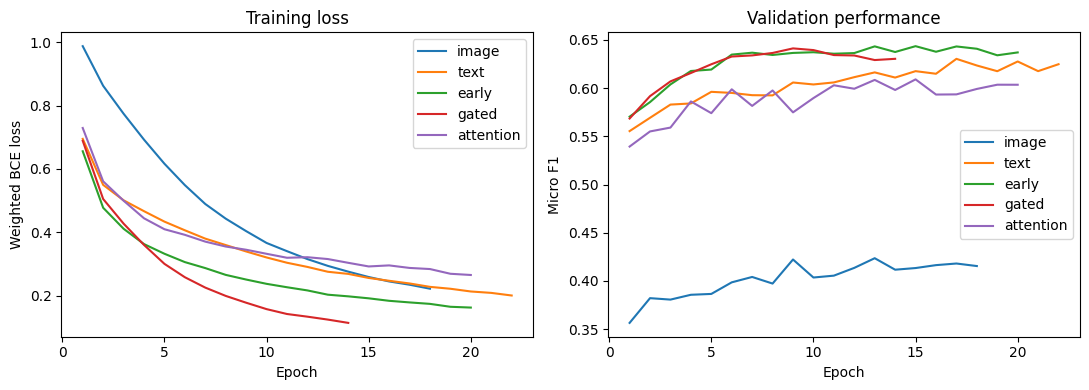

Note: train loss and validation F1 are different metrics; use a comparable train/validation F1 analysis below.


In [19]:
# ---- Step 11A: Epoch curves ----
fig,axs=plt.subplots(1,2,figsize=(11,4))
for name,h in histories.items():
    axs[0].plot(h["epoch"],h["train_loss"],label=name)
    axs[1].plot(h["epoch"],h["val_micro_f1"],label=name)
axs[0].set(title="Training loss",xlabel="Epoch",ylabel="Weighted BCE loss")
axs[1].set(title="Validation performance",xlabel="Epoch",ylabel="Micro F1")
for ax in axs: ax.legend()
plt.tight_layout();plt.show()
print("Note: train loss and validation F1 are different metrics; use a comparable train/validation F1 analysis below.")

In [20]:
# ---- Step 11B: Comparable train/validation micro-F1 gaps ----
# Compare training and validation F1 for the selected checkpoint.
gap_rows=[]
for name,net in models_fit.items():
    p_train=predict_prob(net,Xi_tr,Xt_tr)
    p_val=val_probs[name]
    gap_rows.append({"model":name,
      "train_micro_f1":f1_score(y_tr,p_train>=thresholds[name],average="micro",zero_division=0),
      "val_micro_f1":f1_score(y_va,p_val>=thresholds[name],average="micro",zero_division=0)})
gaps=pd.DataFrame(gap_rows).set_index("model")
gaps["train_minus_val"]=gaps["train_micro_f1"]-gaps["val_micro_f1"]
display(gaps.round(4))

,train_micro_f1,val_micro_f1,train_minus_val
model,,,
image,0.6897,0.4267,0.2630
text,0.7776,0.6304,0.1472
early,0.8427,0.6436,0.1992
gated,0.8437,0.6413,0.2025
attention,0.7655,0.6216,0.1439


,genre,support,f1
10,Film-Noir,96,0.353741
18,Short,136,0.356902
14,Musical,254,0.383562
11,History,315,0.414938
15,Mystery,645,0.462777
9,Fantasy,579,0.498946
3,Biography,403,0.510539
13,Music,310,0.560000
16,Romance,1578,0.561259
1,Adventure,799,0.564075


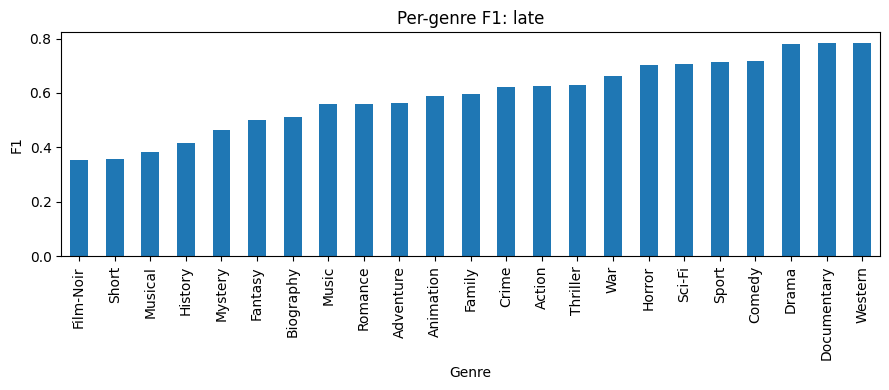

In [21]:
# ---- Step 11C: Per-genre performance for the best test model ----
best_name=results.index[0]
best_pred=(test_probs[best_name]>=thresholds[best_name]).astype(int)
per_genre=pd.DataFrame({"genre":mlb.classes_,"support":y_te.sum(axis=0).astype(int),
    "f1":f1_score(y_te,best_pred,average=None,zero_division=0)})
display(per_genre.sort_values("f1").head(12))
fig,ax=plt.subplots(figsize=(9,4))
per_genre.sort_values("f1").plot.bar(x="genre",y="f1",legend=False,ax=ax)
ax.set(title=f"Per-genre F1: {best_name}",xlabel="Genre",ylabel="F1")
plt.tight_layout();plt.show()

## Prediction error analysis

False-positive and missed genres for individual test movies. These examples can support the error-analysis section of the report; do not infer why a model failed without inspecting the actual movie.

In [22]:
# ---- Step 12A: Movie-level error examples ----
# Movie-level errors for the best model, with false-positive and missed genres.
test_frame = df.iloc[test_idx].reset_index(drop=True)
label_names = np.asarray(mlb.classes_)
true_binary = y_te.astype(bool)
pred_binary = best_pred.astype(bool)
wrong_rows = []
for pos in np.flatnonzero(np.any(true_binary != pred_binary, axis=1)):
    true_genres = set(label_names[true_binary[pos]])
    predicted_genres = set(label_names[pred_binary[pos]])
    wrong_rows.append({
        "id": str(test_frame.iloc[pos]["id"]),
        "plot_excerpt": str(test_frame.iloc[pos]["plot"])[:240],
        "true_genres": ", ".join(sorted(true_genres)),
        "predicted_genres": ", ".join(sorted(predicted_genres)),
        "false_positive_genres": ", ".join(sorted(predicted_genres-true_genres)),
        "missed_genres": ", ".join(sorted(true_genres-predicted_genres)),
        "test_position": int(pos)})
failure_cases = pd.DataFrame(wrong_rows)
exact_match_accuracy = float(np.mean(np.all(true_binary==pred_binary, axis=1)))
print("Best model:", best_name, "| Exact-match accuracy:", round(exact_match_accuracy,4),
      "| Movies with >=1 wrong label:", len(failure_cases))
display(failure_cases.head(15))

Best model: late | Exact-match accuracy: 0.1463 | Movies with >=1 wrong label: 6645


,id,plot_excerpt,true_genres,predicted_genres,false_positive_genres,missed_genres,test_position
0,0061791,"Twenty-seven year old New York window washer, ...","Comedy, Musical","Comedy, Drama, Romance","Drama, Romance",Musical,0
1,1231287,Thea Clayhill is the reckless secretary of arr...,"Comedy, Romance","Comedy, Drama, Romance",Drama,,1
2,0082404,This story of four working-class kids in a sma...,"Comedy, Drama","Drama, Romance",Romance,Comedy,2
3,0114781,Seal Team Commander Casey Ryback has retired f...,"Action, Thriller","Action, Adventure, Crime, Thriller","Adventure, Crime",,4
4,0116913,Director Al Pacino juxtaposes scenes from Rich...,"Documentary, Drama",Documentary,,Drama,5
5,0133152,It is the year 2029: Astronaut Leo Davidson bo...,"Action, Adventure, Sci-Fi, Thriller","Action, Adventure, Fantasy, Sci-Fi, Thriller",Fantasy,,6
6,0064208,"As a child, Bill witnesses the murder of his f...",Western,"Action, Crime, Drama, History, Thriller, Western","Action, Crime, Drama, History, Thriller",,7
7,0064541,Bullied at school and ignored and abused at ho...,"Drama, Family",Drama,,Family,8
8,0061550,An expedition in the South Pacific lands on a ...,"Comedy, Family, Horror, Sci-Fi","Action, Adventure, Fantasy, Horror, Sci-Fi","Action, Adventure, Fantasy","Comedy, Family",9
9,0110173,Director Jean-Luc Godard reflects in this movi...,"Documentary, Drama","Documentary, Music",Music,Drama,10


## Subgroup performance

Descriptive micro/macro F1 for country, language and release-period groups where metadata exists and sample size is at least 30. These differences are not causal evidence of unfairness. Record missing subgroup metadata explicitly.

In [23]:
# ---- Step 13A: Metadata-based subgroup evaluation ----
# Exploratory bias / subgroup audit using metadata actually present in the JSON.
# Do not infer missing country, language or release year. Small groups are excluded.
import re
meta_rows = []
for poster_path in tqdm(df["poster"].tolist(), desc="Loading subgroup metadata"):
    jf = Path(poster_path).with_suffix(".json")
    try:
        obj = json.loads(jf.read_text(encoding="utf-8"))
    except (OSError, ValueError, UnicodeError):
        obj = {}
    def first_value(*keys):
        for key in keys:
            value = obj.get(key)
            if isinstance(value, list):
                value = next((v for v in value if v is not None and str(v).strip()), None)
            if isinstance(value, dict):
                value = None
            if value is not None and str(value).strip():
                return str(value).strip()
        return None
    year_raw = first_value("year", "release_year", "release_date", "released", "publication_date")
    match = re.search(r"(?:18|19|20)\d{2}", year_raw or "")
    year = int(match.group()) if match else np.nan
    meta_rows.append({"id": jf.stem,
                      "country": first_value("country", "countries"),
                      "language": first_value("language", "languages"),
                      "year": year})
meta_df = pd.DataFrame(meta_rows).drop_duplicates("id")
subgroup_frame = test_frame[["id"]].merge(meta_df, on="id", how="left", validate="one_to_one")
assert len(subgroup_frame) == len(y_te)
subgroup_frame["release_period"] = pd.cut(pd.to_numeric(subgroup_frame["year"], errors="coerce"),
    bins=[-np.inf,1989,1999,2009,2019,np.inf],
    labels=["Before 1990","1990s","2000s","2010s","2020+"])
print("Metadata coverage (test movies):")
print(subgroup_frame[["country","language","year"]].notna().sum().to_string())
subgroup_rows=[]
for field in ("country","language","release_period"):
    for value, group in subgroup_frame.groupby(field, observed=True, dropna=True):
        idx = group.index.to_numpy()
        if len(idx) < 30:
            continue
        subgroup_rows.append({"attribute":field, "group":str(value), "movies":len(idx),
                              "micro_f1":float(f1_score(y_te[idx],best_pred[idx],average="micro",zero_division=0)),
                              "macro_f1":float(f1_score(y_te[idx],best_pred[idx],average="macro",zero_division=0))})
subgroup_results = pd.DataFrame(subgroup_rows, columns=["attribute","group","movies","micro_f1","macro_f1"])
if subgroup_results.empty:
    print("No subgroup with at least 30 test movies and usable metadata. Document coverage limitation.")
else:
    display(subgroup_results.sort_values(["attribute","movies"],ascending=[True,False]))
print("Interpretation: subgroup differences are descriptive, not causal fairness findings; genres and sample sizes vary.")

Loading subgroup metadata:   0%|          | 0/25945 [00:00<?, ?it/s]

Metadata coverage (test movies):
country     7781
language    7721
year        7784


,attribute,group,movies,micro_f1,macro_f1
19,country,USA,4482,0.657632,0.604822
18,country,UK,717,0.646475,0.562950
5,country,France,498,0.644615,0.491550
2,country,Canada,234,0.641660,0.550799
10,country,Japan,227,0.622616,0.480663
6,country,Germany,186,0.654959,0.541877
9,country,Italy,180,0.624585,0.529282
16,country,Spain,109,0.601835,0.451735
1,country,Australia,92,0.631164,0.459132
17,country,Sweden,88,0.628866,0.395964


Interpretation: subgroup differences are descriptive, not causal fairness findings; genres and sample sizes vary.


## Computational efficiency

Classifier parameters and time classifier inference on cached features. Report encoder feature-stage time separately. The late-fusion ensemble uses two classifiers.

In [24]:
# ---- Step 14A: Parameters, training time and inference time ----
# Parameter counts and classifier-only inference latency (precomputed features).
# Encoder feature extraction is NOT included in these inference timings.
eff_rows=[]
for name, net in models_fit.items():
    net.eval()
    total = sum(p.numel() for p in net.parameters())
    trainable = sum(p.numel() for p in net.parameters() if p.requires_grad)
    _ = predict_prob(net, Xi_te[:min(128,len(Xi_te))], Xt_te[:min(128,len(Xt_te))])
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    t0=time.perf_counter()
    for _ in range(5):
        _ = predict_prob(net, Xi_te, Xt_te)
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    elapsed = time.perf_counter()-t0
    eff_rows.append({"model":name, "total_parameters":total,
                     "trainable_parameters":trainable,
                     "training_seconds":train_seconds[name],
                     "classifier_ms_per_movie":1000*elapsed/(5*len(Xi_te))})
# Late fusion is an ensemble of two separately trained classifiers.
image_row = next(x for x in eff_rows if x["model"]=="image")
text_row = next(x for x in eff_rows if x["model"]=="text")
eff_rows.append({"model":"late",
                 "total_parameters":image_row["total_parameters"]+text_row["total_parameters"],
                 "trainable_parameters":image_row["trainable_parameters"]+text_row["trainable_parameters"],
                 "training_seconds":image_row["training_seconds"]+text_row["training_seconds"],
                 "classifier_ms_per_movie":image_row["classifier_ms_per_movie"]+text_row["classifier_ms_per_movie"]})
efficiency_df = pd.DataFrame(eff_rows)
display(efficiency_df.round(4))
print("Feature-stage wall time (includes cache loading if reused):",round(FEATURE_STAGE_SECONDS,2),"seconds")
print("Classifier latency excludes EfficientNet/BERT preprocessing and encoding.")

,model,total_parameters,trainable_parameters,training_seconds,classifier_ms_per_movie
0,image,596503,596503,7.9283,0.0028
1,text,596503,596503,9.5236,0.0028
2,early,1055255,1055255,8.0200,0.0027
3,gated,727831,727831,7.3311,0.0032
4,attention,859671,859671,12.7386,0.0035
5,late,1193006,1193006,17.4520,0.0056


Feature-stage wall time (includes cache loading if reused): 627.83 seconds
Classifier latency excludes EfficientNet/BERT preprocessing and encoding.


## Results and figure exports

Outputs include genre frequency, model comparison, training curves, per-genre F1, token lengths, poster dimensions, subgroup metrics and confusion-style error counts. Export the split assignments and experiment configuration so results are reproducible.

In [25]:
# ---- Step 15A: Save model checkpoints and experiment metadata ----
import json
from pathlib import Path
OUT = ROOT / 'mmimdb_final_outputs'
OUT.mkdir(parents=True, exist_ok=True)
results.to_csv(OUT / 'test_metrics.csv')
gaps.to_csv(OUT / 'overfitting_gaps.csv')
per_genre.to_csv(OUT / 'per_genre_f1.csv', index=False)
with open(OUT / 'experiment_config.json', 'w') as f:
    json.dump({'seed': SEED, 'split_method': SPLIT_METHOD,
               'train': len(train_idx), 'validation': len(val_idx), 'test': len(test_idx),
               'movies': len(df), 'genres': list(mlb.classes_),
               'thresholds': thresholds, 'late_image_weight': best_weight,
               'feature_encoders': ['EfficientNet-B0', 'bert-base-uncased']}, f, indent=2)
for name, model in models_fit.items():
    torch.save(model.cpu().state_dict(), OUT / f'{name}_model.pt')
    model.to(DEVICE)
print('Saved outputs to:', OUT)
print('Best test model:', results.index[0])

Saved outputs to: /content/mmimdb_final_outputs
Best test model: late


In [26]:
# ---- Step 15B: Export figures and audit tables ----
# Export publication-ready figures and supporting audit tables.
# This cell runs after the existing checkpoint/config export cell.
FIG_DIR = OUT / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(11,5))
pd.Series(Y.sum(axis=0), index=mlb.classes_).sort_values(ascending=False).plot.bar(ax=ax)
ax.set(title="Genre frequencies in retained MM-IMDb movies",xlabel="Genre",ylabel="Movies")
fig.tight_layout(); fig.savefig(FIG_DIR/"genre_distribution.png",dpi=250,bbox_inches="tight");plt.close(fig)

fig, ax = plt.subplots(figsize=(10,5))
results[["micro_f1","macro_f1","weighted_f1"]].plot.bar(ax=ax)
ax.set(title="Held-out test F1 by model",xlabel="Model",ylabel="F1",ylim=(0,1))
fig.tight_layout();fig.savefig(FIG_DIR/"model_comparison.png",dpi=250,bbox_inches="tight");plt.close(fig)

fig, axs = plt.subplots(1,2,figsize=(12,4))
for name,h in histories.items():
    axs[0].plot(h["epoch"],h["train_loss"],label=name)
    axs[1].plot(h["epoch"],h["val_micro_f1"],label=name)
axs[0].set(title="Training loss",xlabel="Epoch",ylabel="Weighted BCE loss")
axs[1].set(title="Validation micro-F1",xlabel="Epoch",ylabel="Micro-F1")
for ax in axs:ax.legend(fontsize=8)
fig.tight_layout();fig.savefig(FIG_DIR/"training_curves.png",dpi=250,bbox_inches="tight");plt.close(fig)

fig,ax=plt.subplots(figsize=(11,5))
per_genre.sort_values("f1").plot.bar(x="genre",y="f1",ax=ax,legend=False)
ax.set(title=f"Per-genre F1 for {best_name}",xlabel="Genre",ylabel="F1",ylim=(0,1))
fig.tight_layout();fig.savefig(FIG_DIR/"per_genre_f1.png",dpi=250,bbox_inches="tight");plt.close(fig)

fig,ax=plt.subplots(figsize=(8,4))
ax.hist(np.minimum(text_audit_df["bert_tokens"],1000),bins=45)
ax.axvline(BERT_MAX_LENGTH,color="red",linestyle="--",label="160-token limit")
ax.set(title="BERT plot-summary token lengths (capped at 1,000)",xlabel="Tokens",ylabel="Movies")
ax.legend();fig.tight_layout();fig.savefig(FIG_DIR/"bert_token_lengths.png",dpi=250,bbox_inches="tight");plt.close(fig)

image_quality_df.to_csv(OUT/"poster_quality.csv",index=False)
text_audit_df.to_csv(OUT/"bert_truncation.csv",index=False)
failure_cases.to_csv(OUT/"failure_cases.csv",index=False)
subgroup_results.to_csv(OUT/"subgroup_metrics.csv",index=False)
efficiency_df.to_csv(OUT/"efficiency.csv",index=False)
pd.DataFrame({"id":df["id"],"split":np.select(
    [np.isin(np.arange(len(df)),train_idx),np.isin(np.arange(len(df)),val_idx)],
    ["train","val"],default="test")}).to_csv(OUT/"split_assignments.csv",index=False)
with open(OUT/"experiment_config.json","r") as f:config=json.load(f)
config.update({"bert_max_length":BERT_MAX_LENGTH,
               "feature_stage_seconds_including_cache":round(FEATURE_STAGE_SECONDS,3),
               "poster_audit":image_quality_df["status"].value_counts().to_dict(),
               "bert_truncation_percent":round(100*float(text_audit_df["exceeds_160_tokens"].mean()),3),
               "best_model":str(best_name),
               "official_split_used":SPLIT_METHOD=="supplied official split file"})
with open(OUT/"experiment_config.json","w") as f:json.dump(config,f,indent=2)
print("Export complete:",OUT)
print("PNG figures:",[p.name for p in sorted(FIG_DIR.glob("*.png"))])
print("CSV tables:",[p.name for p in sorted(OUT.glob("*.csv"))])
print("IMPORTANT: Save the executed notebook separately. The output directory may contain large checkpoints.")
# ---- Extra visual evidence: poster dimensions and subgroup performance ----
fig, ax = plt.subplots(figsize=(8, 5))
valid_sizes = image_quality_df.dropna(subset=['width', 'height'])
ax.scatter(valid_sizes['width'], valid_sizes['height'], s=3, alpha=0.2)
ax.set(title='Poster dimensions', xlabel='Width (pixels)', ylabel='Height (pixels)')
fig.tight_layout()
fig.savefig(FIG_DIR / 'poster_dimensions.png', dpi=250, bbox_inches='tight')
plt.close(fig)

if not subgroup_results.empty:
    fig, ax = plt.subplots(figsize=(11, 5))
    shown = subgroup_results.sort_values('movies', ascending=False).head(15)
    ax.bar(shown['attribute'] + ': ' + shown['group'], shown['micro_f1'])
    ax.set(title='Exploratory subgroup micro-F1 (15 largest eligible groups)',
           xlabel='Subgroup', ylabel='Micro-F1', ylim=(0, 1))
    ax.tick_params(axis='x', rotation=75)
    fig.tight_layout()
    fig.savefig(FIG_DIR / 'subgroup_micro_f1.png', dpi=250, bbox_inches='tight')
    plt.close(fig)

print('All final figures:', len(list(FIG_DIR.glob('*.png'))))


Export complete: /content/mmimdb_final_outputs
PNG figures: ['bert_token_lengths.png', 'genre_distribution.png', 'model_comparison.png', 'per_genre_f1.png', 'training_curves.png']
CSV tables: ['bert_truncation.csv', 'efficiency.csv', 'failure_cases.csv', 'overfitting_gaps.csv', 'per_genre_f1.csv', 'poster_quality.csv', 'split_assignments.csv', 'subgroup_metrics.csv', 'test_metrics.csv']
IMPORTANT: Save the executed notebook separately. The output directory may contain large checkpoints.
All final figures: 7


## Output verification

The exported archive includes metrics, figures, CSVs, configurations and checkpoints. It may be large. Upload only code, README and appropriately sized result artifacts to GitHub; do not upload the raw 8.7 GB dataset. The report, slides and presentation video are separate assessment deliverables.

In [27]:
# ---- Step 16A: Check files before creating an export ZIP ----
required = [
    OUT / 'test_metrics.csv',
    OUT / 'experiment_config.json',
    OUT / 'failure_cases.csv',
    OUT / 'subgroup_metrics.csv',
    OUT / 'efficiency.csv',
    FIG_DIR / 'genre_distribution.png',
    FIG_DIR / 'model_comparison.png',
    FIG_DIR / 'training_curves.png',
    FIG_DIR / 'per_genre_f1.png',
    FIG_DIR / 'bert_token_lengths.png',
    FIG_DIR / 'poster_dimensions.png'
]
missing = [str(path) for path in required if not path.exists()]
if missing:
    raise RuntimeError('Missing required outputs: ' + ', '.join(missing))

zip_path = shutil.make_archive(str(ROOT / 'MMIMDb_Final_Results'), 'zip', root_dir=str(OUT))
print('Export verified:', zip_path)
print('Files:', sum(path.is_file() for path in OUT.rglob('*')))
print('Size (MB):', round(Path(zip_path).stat().st_size / (1024**2), 1))
print('Notebook outputs are saved separately through Colab File > Download > .ipynb')

Export verified: /content/MMIMDb_Final_Results.zip
Files: 22
Size (MB): 15.5
Notebook outputs are saved separately through Colab File > Download > .ipynb
